This is a file to do exploratory data analysis on the SMAP and MSL data from NASA

In [40]:
import numpy as np
import pandas as pd

In [75]:
anomalies = pd.read_csv("labeled_anomalies.csv")
anomalies

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307
...,...,...,...,...,...
77,P-11,MSL,"[[1778, 1898], [1238, 1344]]","[point, point]",3535
78,D-15,MSL,"[[1500, 2140]]",[point],2158
79,D-16,MSL,"[[600, 1250]]",[contextual],2191
80,M-7,MSL,"[[940, 1040]]",[point],2156


In [42]:
#The spacecraft column has two possible values: Soil Moisture Active Passive (SMAP) satellite 
# or Mars Science Laboratory (MSL) rover, Curiosity
anomalies.spacecraft.unique()

array(['SMAP', 'MSL'], dtype=object)

In [43]:
#We make two anomalies dataset, one for SMAP and one for MSL
anomalies_SMAP = anomalies[anomalies.spacecraft=="SMAP"]
anomalies_MSL = anomalies[anomalies.spacecraft=="MSL"]

Now let us try to understand telemetary data. The channel ID is a unique ID that is exactly on one spacecraft. The first column represents the readings of the Telmetary channel which is normalized to between -1 and 1. The other columns record any other change made in the spacecraft before recording the telemetary reading. This is important, for instance, you would want to know that a heater was turned on before recording the temperature.

It is important to figure out which channel_id belongs to which spacecraft before analyzing data. We obtain this information from the anomalies_SMAP or anomalies_MSL variables which contains the list of channel_id for SMAP and MSL respectively stored under the column "chan_id"

There are two directories data/test and data/train.  Train only contains a subset of rows and Test contains all the rows. So we perform EDA on the test data which is all the information. 

In [44]:
#Just to get a feel for that data, let us look at P1-channel which belongs to SMAP. This will have
# (1 + 24) features
P1=np.load("data/data/test/P-1.npy")
P1=pd.DataFrame(P1)

In [45]:
#Let us drop the one hot encoded feature columns that have not changed at all.
drop = [col for col in P1.columns.tolist() if P1[col].unique().size==1]
drop


[4, 10, 15, 16, 20, 23, 24]

In [46]:
P1 = P1[[i for i in P1.columns.tolist() if i not in drop]]

In [47]:
#There are still some duplicated columns. We can use the following to know what is duplicated.
repeated = P1.T.duplicated()
repeated

0     False
1     False
2     False
3     False
5     False
6     False
7     False
8     False
9     False
11    False
12    False
13    False
14     True
17    False
18     True
19    False
21    False
22    False
dtype: bool

In [48]:
#Let us drop the repeated columns i.e 14 and 18
P1 = P1.drop(columns=[14,18])


In [49]:
#One small problem to note is that anomaly_sequences column is actually a string
anomalies_SMAP[anomalies_SMAP.chan_id=="P-1"]["anomaly_sequences"][0]

'[[2149, 2349], [4536, 4844], [3539, 3779]]'

In [50]:
#We use ast to convert a string to a list
import ast
anomaly_sequence = ast.literal_eval(anomalies_SMAP[anomalies_SMAP.chan_id=="P-1"]["anomaly_sequences"][0])
#Now we have a list of lists
anomaly_sequence

[[2149, 2349], [4536, 4844], [3539, 3779]]

In [51]:
#here is a snapshot of our data so far
P1

,0,1,2,3,5,6,7,8,9,11,12,13,17,19,21,22
0,-0.695162,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.685704,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.725719,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.761368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.745362,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8500,0.293561,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8501,0.341579,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0
8502,-0.316115,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8503,-0.297199,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [52]:
#We will store all the one hot encoded columns in a list
OHF=P1.columns.tolist()[1:]
print(OHF)
print(f"There are {len(OHF)} one hot encoded features")

[1, 2, 3, 5, 6, 7, 8, 9, 11, 12, 13, 17, 19, 21, 22]
There are 15 one hot encoded features


# EDA
Now let us plot the P-1 channel reading. We will also mark the anomalies in red.

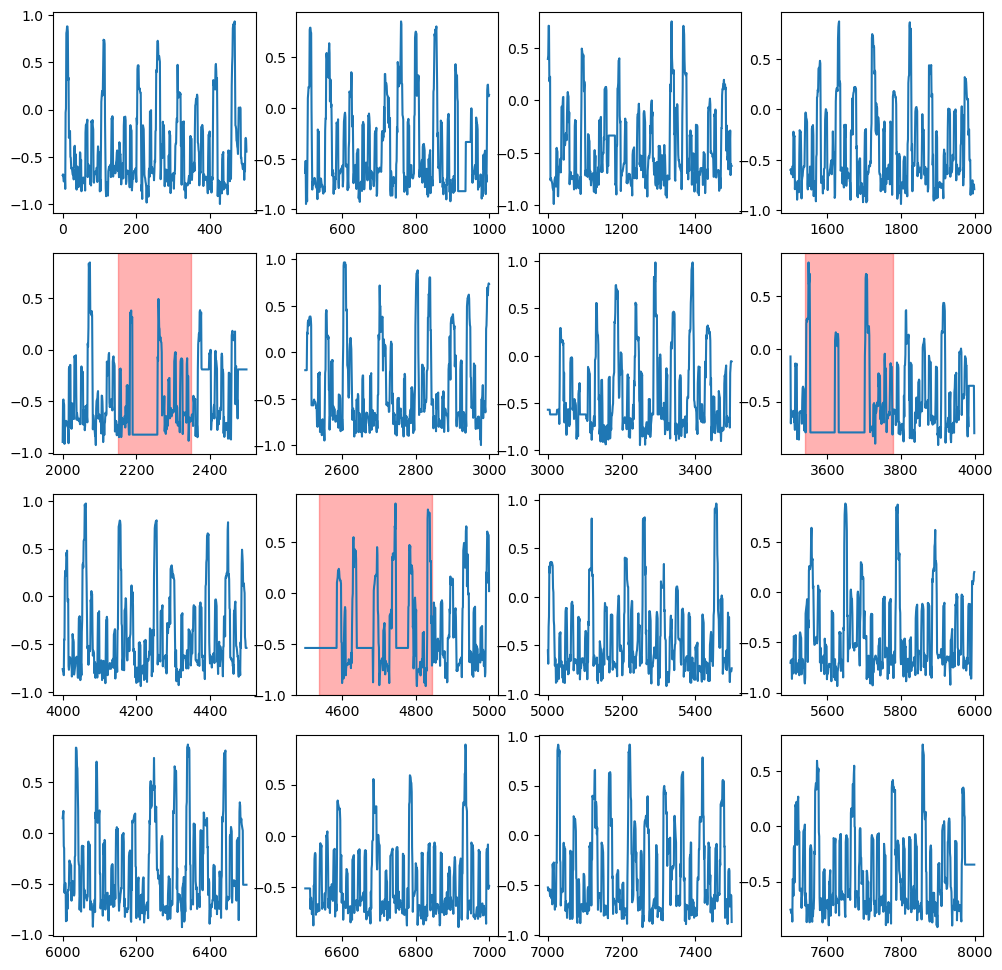

In [53]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12,12))
axes = axes.flatten()

for i in range(16):
    axes[i].plot(P1.index[i*500:(i+1)*500] , P1.iloc[i*500:(i+1)*500,0])
    for anomaly in anomaly_sequence:
        if (anomaly[0]>=i*500) and (anomaly[1]<=(i+1)*500):
            axes[i].axvspan(anomaly[0], anomaly[1], color="red", alpha=0.3)

(array([ 719., 3161., 1476.,  792.,  998.,  502.,  420.,  172.,  159.,
         106.]),
 array([-1.00000000e+00, -8.00000000e-01, -6.00000000e-01, -4.00000000e-01,
        -2.00000000e-01,  2.22044605e-16,  2.00000000e-01,  4.00000000e-01,
         6.00000000e-01,  8.00000000e-01,  1.00000000e+00]),
 <BarContainer object of 10 artists>)

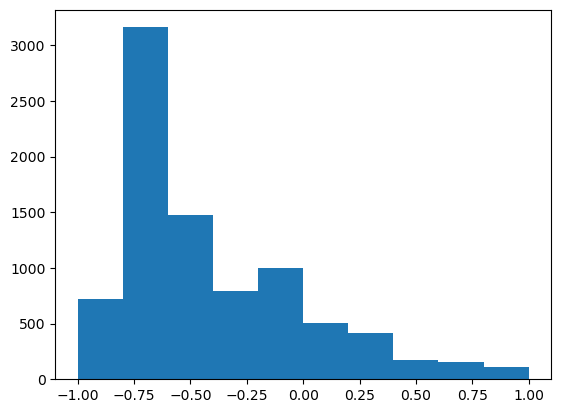

In [54]:
plt.hist(P1[0])

The first anaylsis of the time series of to understand what the period is. There are two methods we can use ACF and FFT. First let us look at ACF.

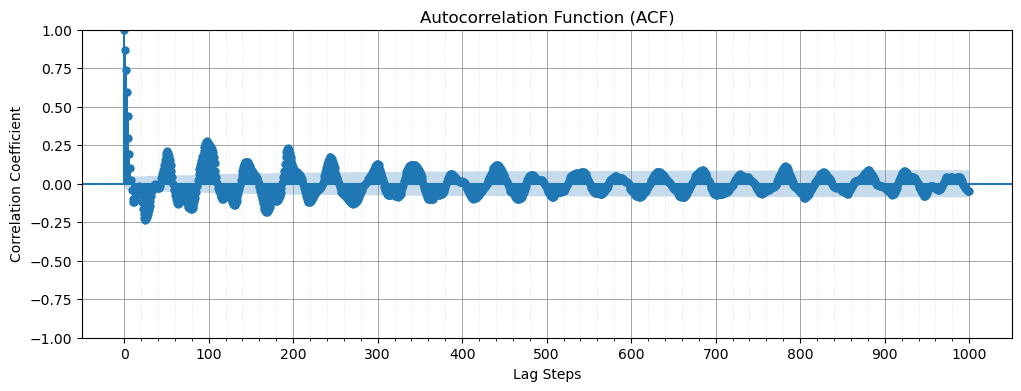

In [55]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf


fig, ax = plt.subplots(figsize=(12, 4))

plot_acf(P1[0], ax=ax, lags=1000)

plt.title('Autocorrelation Function (ACF)')
plt.xlabel('Lag Steps')
plt.ylabel('Correlation Coefficient')

# 1. Set explicit ticks every 100 lags (and minor ticks every 20) for easy reading
ax.set_xticks(np.arange(0, 1001, 100))
ax.set_xticks(np.arange(0, 1001, 20), minor=True)

# 2. Add the background grid for both major and minor ticks
ax.grid(True, which='major', linestyle='-', linewidth=0.7, alpha=0.7, color='gray')
ax.grid(True, which='minor', linestyle='--', linewidth=0.5, alpha=0.5, color='lightgray')

plt.show()

We see from the above figure that that two peaks are roughly 100 apart. So the period is approximately 50. Let us plot some of these. The red vertical lines appear whenover one of the additional featues is turned on.

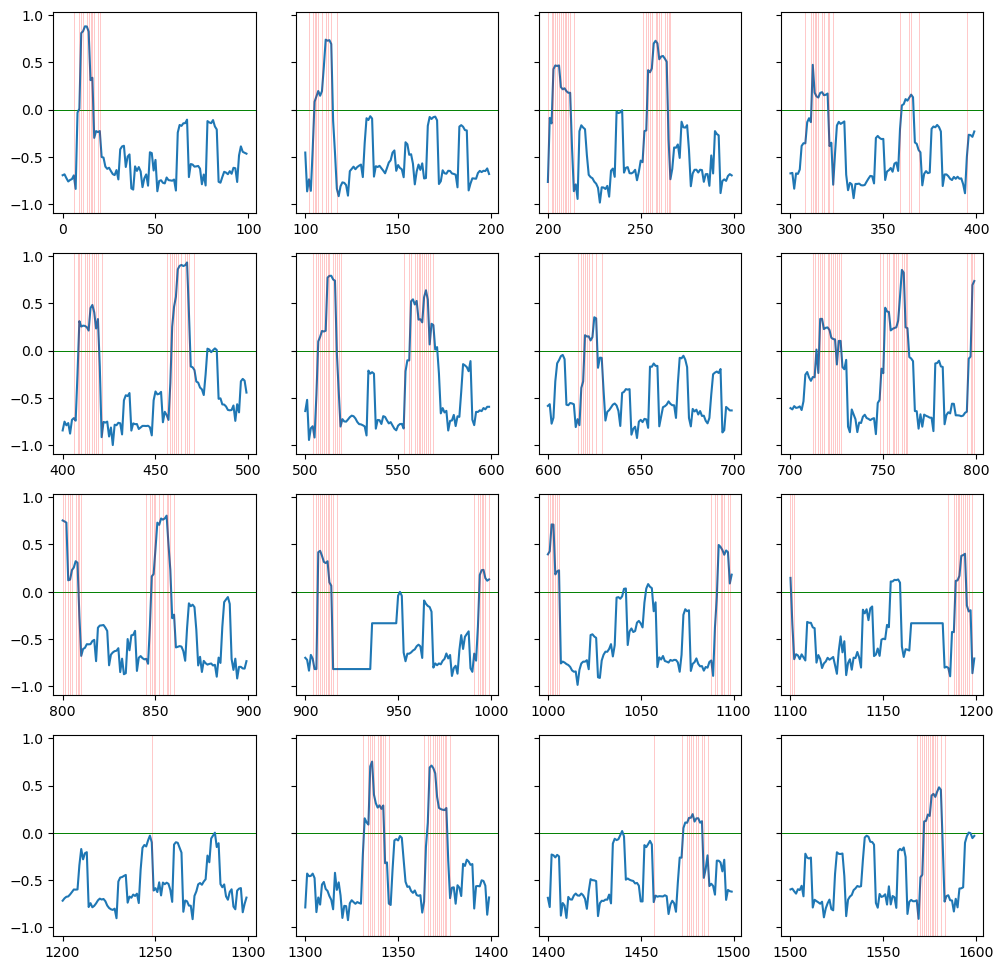

In [71]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12,12), sharey=True)
axes = axes.flatten()

for i in range(16):
    axes[i].axhline(0, color= "green", lw=0.7)
    axes[i].plot(P1.index[i*100:(i+1)*100] , P1.iloc[i*100:(i+1)*100,0])
    for j in range(i*100,(i+1)*100):
            if P1.iloc[j, 1:].any():
                axes[i].axvline(j, color = "red", alpha=0.3, lw=0.5)


Now, let us plot the anomaly region [2000,2400] and see how it looks different.

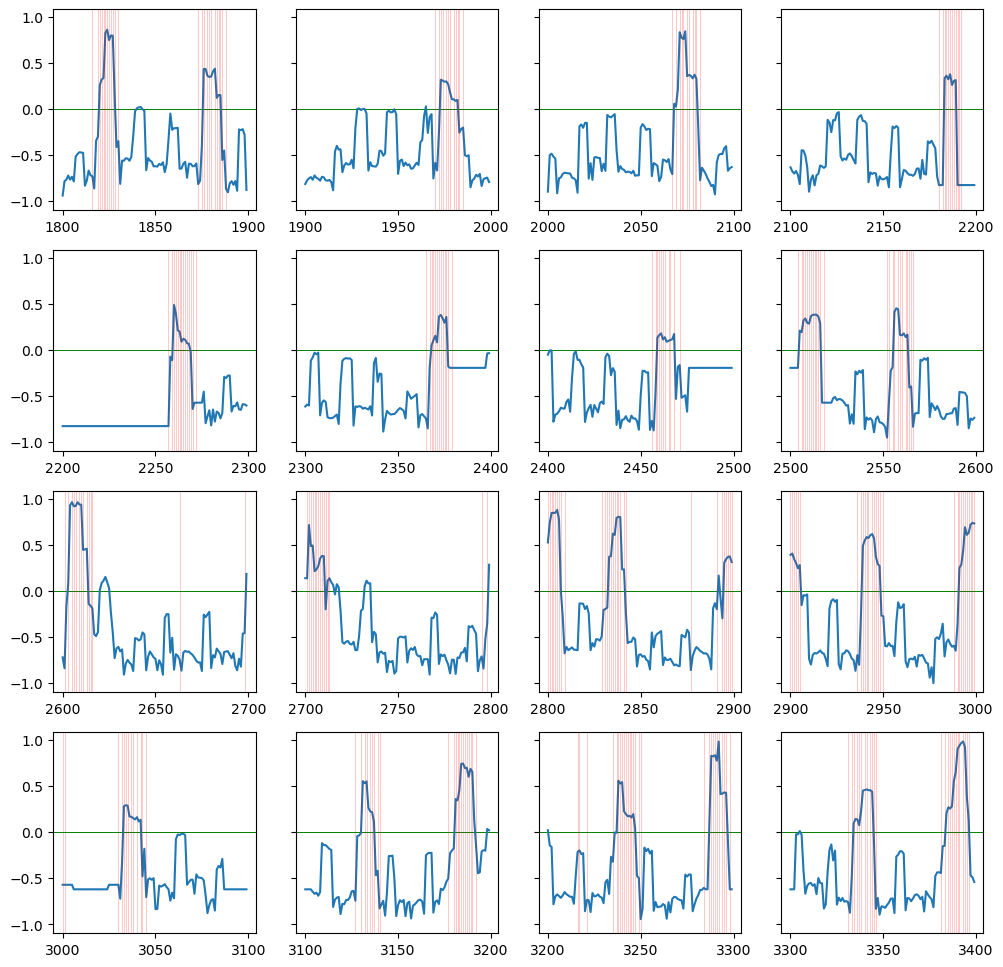

In [72]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(12,12), sharey=True)
axes = axes.flatten()

for i in range(16):
    axes[i].axhline(0, color="green", lw=0.7)
    axes[i].plot(P1.index[1800+i*100:1800+(i+1)*100] , P1.iloc[1800+i*100:1800+(i+1)*100,0])
    for j in range(1800+i*100,1800+(i+1)*100):
            if P1.iloc[j, 1:].any():
                axes[i].axvline(j, color = "red", alpha=0.3, lw=0.5)

We also need to understand how the features affect the telemetary reading. Let us first understand how often the features appear.

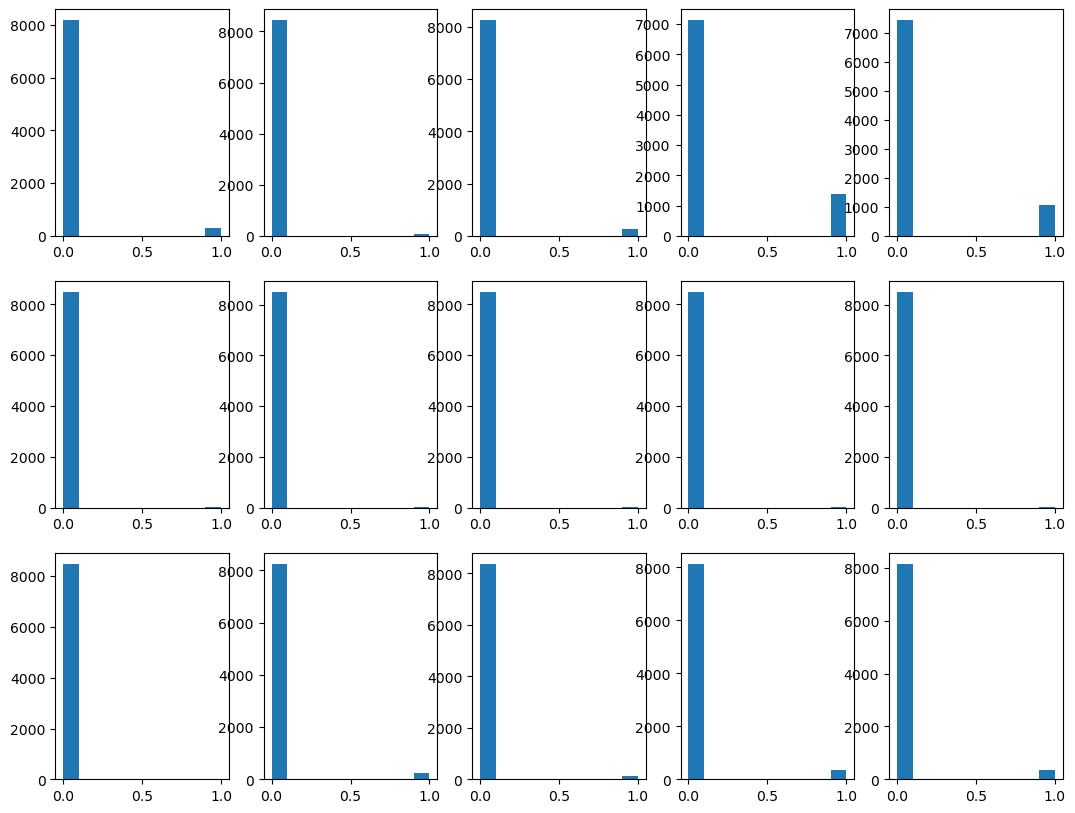

In [17]:
fig , axes = plt.subplots(nrows=3, ncols=5, figsize=(13,10))
axes = axes.flatten()
for i in range(len(OHF)):
    axes[i].hist(P1[[OHF[i]]])

The one hot encoded features take the value of 1 very very few times. It is less than 500 except for column 4 and 5. Let us see how sparse they are. Again, let us do it 2000 at a time.

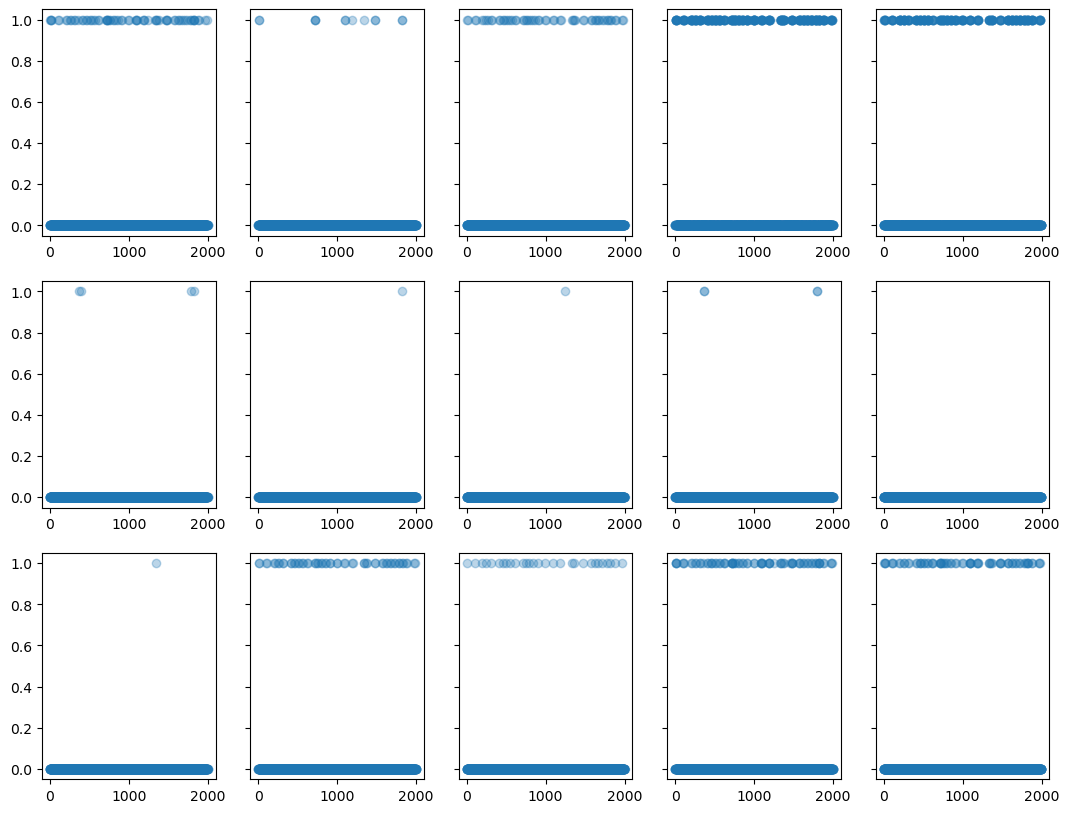

In [57]:
fig, axes = plt.subplots(nrows=3, ncols=5, figsize=(13,10), sharey=True)
axes = axes.flatten()
for i in range(len(OHF)):
    axes[i].scatter(P1.index[0:2000], P1[OHF[i]][0:2000], alpha=0.3)

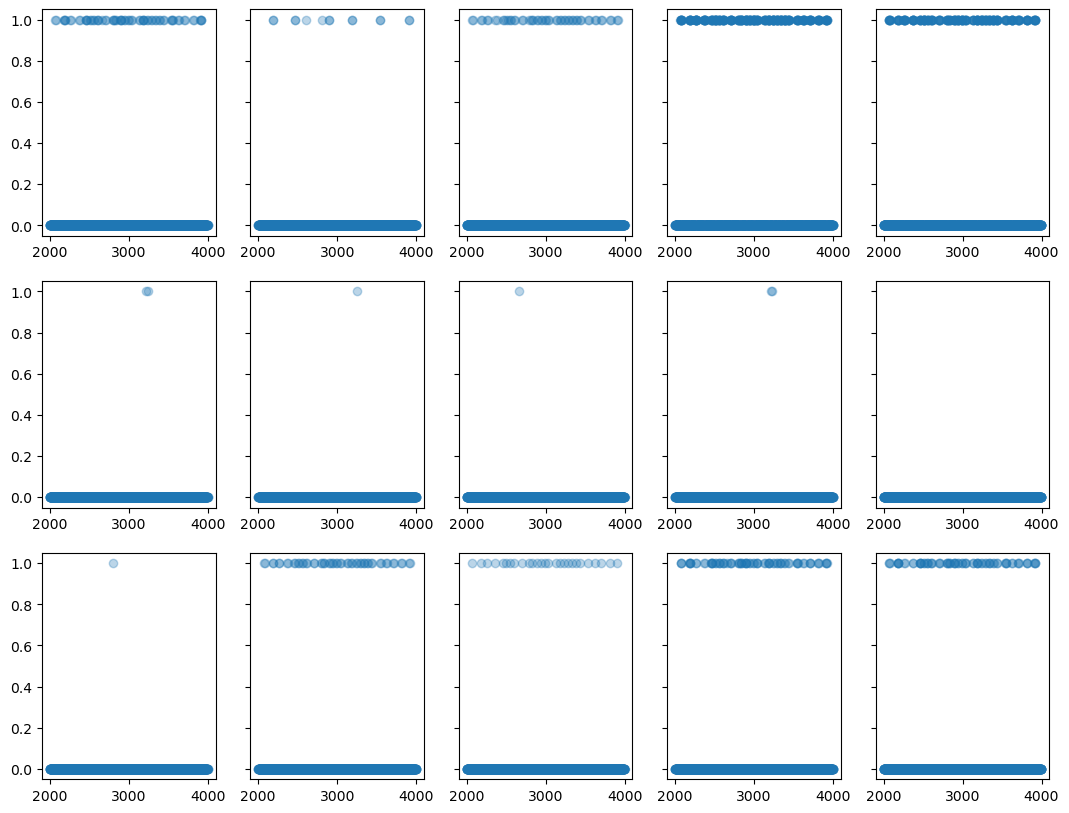

In [73]:
fig, axes = plt.subplots(nrows=3, ncols=5, figsize=(13,10), sharey=True)
axes = axes.flatten()
for i in range(len(OHF)):
    axes[i].scatter(P1.index[2000:4000], P1[OHF[i]][2000:4000], alpha=0.3)

We see that we can drop some of these columns as they are very sparse. So we must do some PCA.

# Models
Now that we have see the graphs, let us just fit a model naively and try to predict. For our training data we are going to use the values upto 2000 where there are no anomalies. After that we will try to fit the model on all of our data. We will use a regressor model to predict what the correct reading should be. The anomalies will occur at those places where there is a big error between the predicted values and actual values. Note that we could also think about using a classifier model; this could be more useful for point anamoly. Perhaps a way to use classifier model for contextual anomaly is to consider sub-intervals as features with a sliding scale.

On the other hand, the whole problem could be treated as a categorical problem where we predict if something is an anomaly or not. There is a very big class imbalance so logistic regression is probably a bad idea. There are classification models that can handle such large class imbalances like XGBoost, Random Forests etc.